# 🏥 BUSI Breast Ultrasound — Complete Pipeline
## Preprocessing → Model → Training → Evaluation → Uncertainty → Gradio

**Dataset:** BUSI (Breast Ultrasound Images) — 3 classes: Normal / Benign / Malignant

---

| Part | Content |
|---|---|
| **Part 1** | Setup — install, drive mount, config |
| **Part 2** | Preprocessing — denoise, CLAHE, sharpen, augment, save |
| **Part 3** | Dataset — PyTorch Dataset class + DataLoader |
| **Part 4** | Model — UNet (segmentation) + TumorClassifier (classification) |
| **Part 5** | Training — Stage 1: UNet → Stage 2: Classifier → Stage 3: Joint |
| **Part 6** | Evaluation — accuracy, dice, F1, confusion matrix |
| **Part 7** | Uncertainty — MC Dropout, uncertainty maps, correlation |
| **Part 8** | Gradio — web app deployment |

> ⚠️ **Enable GPU before running:** Runtime → Change runtime type → T4 GPU

---

---
# 📦 Part 1 — Setup
---

## 1.1 Install Dependencies

In [1]:
# Install required packages
# Run this cell once
import sys
!{sys.executable} -m pip install opencv-python scikit-learn matplotlib pillow tqdm scipy gradio --user -q


[notice] A new release of pip is available: 24.0 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1.2 Mount Google Drive

## 1.3 Configuration

In [2]:
import os, random, math, time
import numpy as np
import torch

# ── Dataset and output paths ─────────────────────────────────────────────────
# ── Change these paths to match your PC ──────────────────────────────────
RAW_DIR  = "C:/Users/User/BUSI_Project/Dataset_BUSI_with_GT"          # original BUSI dataset
DATA_DIR = "C:/Users/User/BUSI_Project/preprocessed_dataset"          # preprocessed images saved here
CKPT_DIR = "C:/Users/User/BUSI_Project/checkpoints"                   # model weights saved here
SAVE_DIR = "C:/Users/User/BUSI_Project/results"                       # plots and results saved here

# Create directories if they don't exist
for d in [DATA_DIR, CKPT_DIR, SAVE_DIR]:
    os.makedirs(d, exist_ok=True)

# ── Training hyperparameters ──────────────────────────────────────────────────
IMG_SIZE        = 256    # all images resized to 256x256
BATCH_SIZE      = 8      # images processed per training step
SEG_EPOCHS      = 100    # epochs for UNet segmentation training
CLS_EPOCHS      = 60     # epochs for classifier training
FINETUNE_EPOCHS = 30     # epochs for joint fine-tuning
SEG_LR          = 3e-4   # UNet learning rate
CLS_LR          = 1e-3   # classifier learning rate
NUM_WORKERS     = 0      # Windows e 0 rakha safe (multiprocessing issue)
SEED            = 42     # random seed for reproducibility

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")
print(f"PyTorch: {torch.__version__}")
if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print("\n✅ Config ready")

Device : cuda
PyTorch: 2.5.1+cu121
GPU    : NVIDIA GeForce RTX 3050 6GB Laptop GPU

✅ Config ready


---
# 🔧 Part 2 — Image Preprocessing
---

Raw ultrasound images contain speckle noise that degrades model performance.
Three preprocessing steps are applied before training:

| Step | Method | Purpose |
|---|---|---|
| **Denoising** | `fastNlMeansDenoisingColored` | Remove ultrasound speckle noise |
| **CLAHE** | Contrast Limited Adaptive Histogram Equalization | Enhance tumour visibility |
| **Sharpening** | 3×3 sharpening kernel | Sharpen tumour boundaries |

After preprocessing, each image is augmented 3× (flip, rotate, brightness) to expand the dataset.

## 2.1 Preprocessing and Augmentation Functions

In [3]:
import cv2
import numpy as np
from tqdm import tqdm


def preprocess_image(image):
    """
    Apply three-step preprocessing pipeline to a raw ultrasound image.

    Steps:
        1. Resize to IMG_SIZE x IMG_SIZE
        2. Non-local means denoising  — removes speckle noise
        3. CLAHE on L channel (LAB)   — improves tumour contrast
        4. Sharpening convolution     — accentuates tumour boundaries

    Args:
        image (np.ndarray): RGB uint8 image

    Returns:
        np.ndarray: Preprocessed RGB uint8 image
    """
    # Step 1: Resize
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))

    # Step 2: Denoising — h=10, template window=7, search window=21
    image = cv2.fastNlMeansDenoisingColored(image, None, 10, 10, 7, 21)

    # Step 3: CLAHE applied to L channel in LAB color space
    lab      = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l, a, b  = cv2.split(lab)
    clahe    = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l        = clahe.apply(l)
    image    = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2RGB)

    # Step 4: Sharpening kernel (Laplacian-based)
    kernel = np.array([[0, -1, 0],
                       [-1, 5, -1],
                       [0, -1, 0]])
    image = cv2.filter2D(image, -1, kernel)

    return image


def preprocess_mask(mask):
    """
    Clean and binarise a segmentation mask.

    Steps:
        1. Resize with nearest-neighbour interpolation (preserve binary edges)
        2. Binary threshold at 127
        3. Morphological opening  — remove small noise regions
        4. Morphological closing  — fill small holes inside mask

    Args:
        mask (np.ndarray): Grayscale mask image

    Returns:
        np.ndarray: Binary uint8 mask (values 0 or 255)
    """
    mask   = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    mask   = (mask > 127).astype(np.uint8) * 255
    kernel = np.ones((3, 3), np.uint8)
    mask   = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  kernel)
    mask   = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    return mask


def augment(image, mask):
    """
    Apply random spatial and photometric augmentations.
    The same spatial transform is applied to both image and mask.

    Augmentations:
        - Horizontal flip (p=0.5)
        - Vertical flip   (p=0.5)
        - Random rotation ±20 degrees
        - Random brightness and contrast jitter

    Args:
        image (np.ndarray): Preprocessed RGB uint8 image
        mask  (np.ndarray): Corresponding binary mask

    Returns:
        tuple: (augmented_image, augmented_mask)
    """
    # Horizontal flip
    if np.random.rand() > 0.5:
        image = np.fliplr(image).copy()
        mask  = np.fliplr(mask).copy()

    # Vertical flip
    if np.random.rand() > 0.5:
        image = np.flipud(image).copy()
        mask  = np.flipud(mask).copy()

    # Random rotation — same matrix applied to image and mask
    angle = np.random.uniform(-20, 20)
    M     = cv2.getRotationMatrix2D((IMG_SIZE // 2, IMG_SIZE // 2), angle, 1)
    image = cv2.warpAffine(image, M, (IMG_SIZE, IMG_SIZE),
                            borderMode=cv2.BORDER_REFLECT)
    mask  = cv2.warpAffine(mask,  M, (IMG_SIZE, IMG_SIZE),
                            flags=cv2.INTER_NEAREST,
                            borderMode=cv2.BORDER_REFLECT)

    # Brightness and contrast jitter
    alpha = np.random.uniform(0.9, 1.2)
    beta  = np.random.uniform(-15, 15)
    image = np.clip(alpha * image + beta, 0, 255).astype(np.uint8)

    return image, mask


print("✅ Preprocessing functions defined")

✅ Preprocessing functions defined


## 2.2 Process and Save Entire Dataset

In [4]:
# Each raw image is preprocessed and saved, then augmented AUG_PER_IMAGE times.
# Final dataset size: original + (AUG_PER_IMAGE × original) per class

CLASSES       = ["normal", "benign", "malignant"]
AUG_PER_IMAGE = 3  # number of augmented copies per original image

# Create output class folders
for cls in CLASSES:
    os.makedirs(os.path.join(DATA_DIR, cls), exist_ok=True)

for cls in CLASSES:
    cls_dir = os.path.join(RAW_DIR, cls)
    images  = [f for f in sorted(os.listdir(cls_dir))
                if f.endswith(".png") and not f.endswith("_mask.png")]

    print(f"\nProcessing {cls} — {len(images)} raw images")

    for img_file in tqdm(images):
        img_path  = os.path.join(cls_dir, img_file)
        mask_path = os.path.join(cls_dir, img_file.replace(".png", "_mask.png"))

        if not os.path.exists(mask_path):
            continue

        # Load raw image and mask
        image = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        mask  = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # Apply preprocessing pipeline
        image = preprocess_image(image)
        mask  = preprocess_mask(mask)
        base  = img_file.replace(".png", "")

        # Save preprocessed original
        cv2.imwrite(os.path.join(DATA_DIR, cls, f"{base}.png"),
                    cv2.cvtColor(image, cv2.COLOR_RGB2BGR))
        cv2.imwrite(os.path.join(DATA_DIR, cls, f"{base}_mask.png"), mask)

        # Save augmented versions
        for i in range(AUG_PER_IMAGE):
            aug_img, aug_mask = augment(image.copy(), mask.copy())
            cv2.imwrite(os.path.join(DATA_DIR, cls, f"{base}_aug{i}.png"),
                        cv2.cvtColor(aug_img, cv2.COLOR_RGB2BGR))
            cv2.imwrite(os.path.join(DATA_DIR, cls, f"{base}_aug{i}_mask.png"), aug_mask)

print("\n✅ Preprocessing complete")
for cls in CLASSES:
    n = len([f for f in os.listdir(os.path.join(DATA_DIR, cls))
             if f.endswith(".png") and not f.endswith("_mask.png")])
    print(f"   {cls:12s}: {n} images saved")


Processing normal — 131 raw images


100%|████████████████████████████████████████████████████████████████████████████████| 131/131 [00:31<00:00,  4.11it/s]



Processing benign — 454 raw images


100%|████████████████████████████████████████████████████████████████████████████████| 454/454 [01:41<00:00,  4.47it/s]



Processing malignant — 208 raw images


100%|████████████████████████████████████████████████████████████████████████████████| 208/208 [00:52<00:00,  3.99it/s]


✅ Preprocessing complete
   normal      : 532 images saved
   benign      : 1748 images saved
   malignant   : 840 images saved


---
# 📂 Part 3 — Dataset and DataLoader
---

## 3.1 BUSIDataset Class

In [5]:
import cv2
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

CLASS_MAP   = {"normal": 0, "benign": 1, "malignant": 2}
CLASS_NAMES = ["normal", "benign", "malignant"]


class BUSIDataset(Dataset):
    """
    PyTorch Dataset for the preprocessed BUSI dataset.

    Each sample returns:
        image (Tensor): shape [3, H, W], float32, ImageNet-normalised
        mask  (Tensor): shape [1, H, W], float32, binary (0 / 1)
        label (Tensor): scalar int64  — 0=normal, 1=benign, 2=malignant

    The dataset is split deterministically using a fixed seed so that
    train / val / test splits are consistent across runs.
    """

    def __init__(self, root_dir, split="train", val_ratio=0.15, test_ratio=0.15,
                 augment=True, seed=42):
        super().__init__()
        self.augment = augment and (split == "train")

        # Collect all (image_path, mask_path, label) tuples
        samples = []
        for cls_name, label in CLASS_MAP.items():
            cls_dir = os.path.join(root_dir, cls_name)
            if not os.path.isdir(cls_dir):
                raise FileNotFoundError(f"Directory not found: {cls_dir}")
            all_files = sorted(os.listdir(cls_dir))
            images    = [f for f in all_files
                         if not f.endswith("_mask.png") and f.endswith(".png")]
            for img_file in images:
                img_path  = os.path.join(cls_dir, img_file)
                mask_path = os.path.join(cls_dir, img_file.replace(".png", "_mask.png"))
                if os.path.exists(mask_path):
                    samples.append((img_path, mask_path, label))

        # Deterministic stratified split
        rng     = np.random.default_rng(seed)
        indices = rng.permutation(len(samples))
        n_test  = int(len(samples) * test_ratio)
        n_val   = int(len(samples) * val_ratio)

        if   split == "test":  chosen = indices[:n_test]
        elif split == "val":   chosen = indices[n_test : n_test + n_val]
        else:                  chosen = indices[n_test + n_val :]

        self.samples = [samples[i] for i in chosen]

        # ImageNet normalisation (mean and std from ImageNet statistics)
        self.img_transform = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                  std=[0.229, 0.224, 0.225]),
        ])

    def _augment(self, image, mask):
        """Runtime augmentation applied only to the training split."""
        if np.random.rand() > 0.5:
            image, mask = np.fliplr(image).copy(), np.fliplr(mask).copy()
        if np.random.rand() > 0.5:
            image, mask = np.flipud(image).copy(), np.flipud(mask).copy()
        angle = np.random.uniform(-15, 15)
        M     = cv2.getRotationMatrix2D((IMG_SIZE // 2, IMG_SIZE // 2), angle, 1)
        image = cv2.warpAffine(image, M, (IMG_SIZE, IMG_SIZE))
        mask  = cv2.warpAffine(mask,  M, (IMG_SIZE, IMG_SIZE))
        alpha, beta = np.random.uniform(0.8, 1.2), np.random.uniform(-20, 20)
        image = np.clip(alpha * image + beta, 0, 255).astype(np.uint8)
        return image, mask

    def __getitem__(self, idx):
        img_path, mask_path, label = self.samples[idx]

        image = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))

        mask  = cv2.resize(cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE),
                           (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
        mask  = (mask > 127).astype(np.uint8)

        if self.augment:
            image, mask = self._augment(image, mask)

        image_tensor = self.img_transform(Image.fromarray(image))
        mask_tensor  = torch.from_numpy(mask).unsqueeze(0).float()
        return image_tensor, mask_tensor, torch.tensor(label, dtype=torch.long)

    def __len__(self):
        return len(self.samples)


def get_loaders(root_dir, batch_size=8, num_workers=2):
    """Build train, validation and test DataLoaders from the preprocessed dataset."""
    train_ds = BUSIDataset(root_dir, split="train", augment=True)
    val_ds   = BUSIDataset(root_dir, split="val",   augment=False)
    test_ds  = BUSIDataset(root_dir, split="test",  augment=False)
    kw = dict(num_workers=num_workers, pin_memory=True)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  **kw)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, **kw)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, **kw)
    print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")
    return train_loader, val_loader, test_loader


train_loader, val_loader, test_loader = get_loaders(DATA_DIR, BATCH_SIZE, NUM_WORKERS)

Train: 2184 | Val: 468 | Test: 468


## 3.2 Visualise Sample Batch

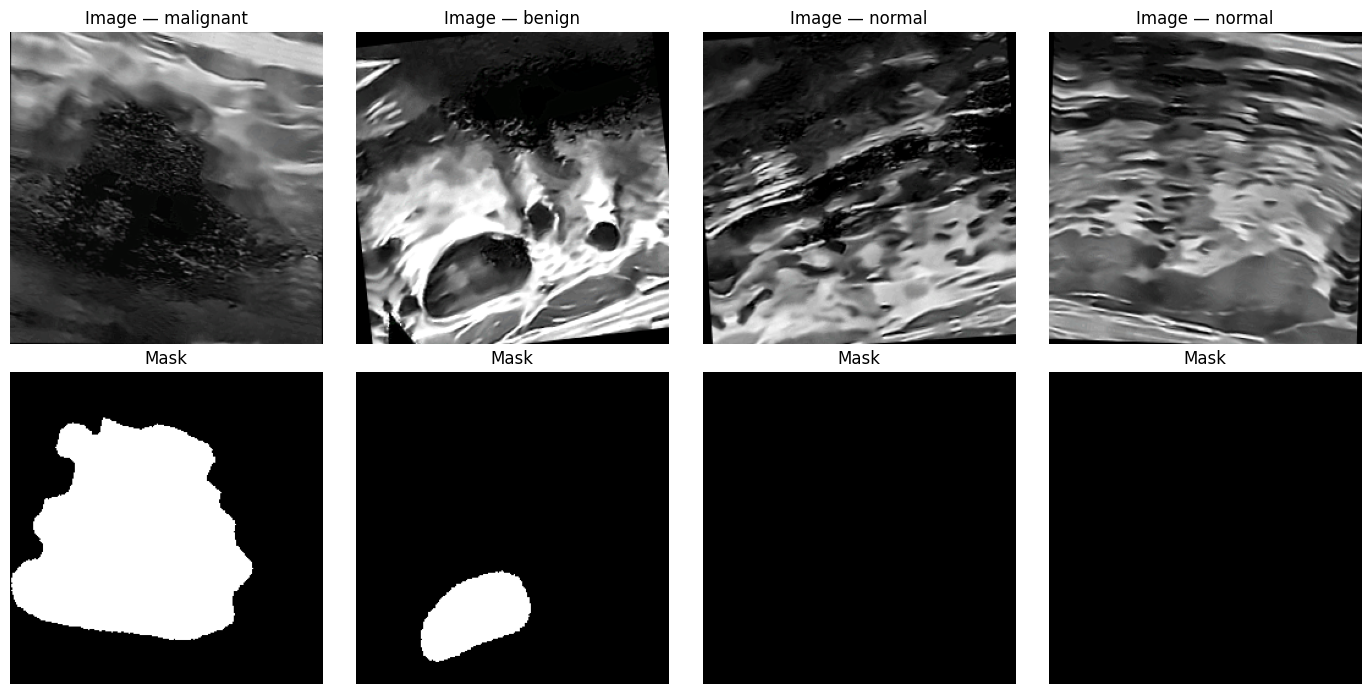

In [6]:
import matplotlib.pyplot as plt


def denorm(t):
    """Reverse ImageNet normalisation for visualisation."""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


imgs, masks, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i in range(min(4, len(imgs))):
    axes[0, i].imshow(denorm(imgs[i]))
    axes[0, i].set_title(f"Image — {CLASS_NAMES[labels[i].item()]}")
    axes[0, i].axis("off")
    axes[1, i].imshow(masks[i, 0].numpy(), cmap="gray")
    axes[1, i].set_title("Mask")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

---
# 🧠 Part 4 — Model Architecture
---

### Model 1 — UNet (Segmentation)
Predicts a pixel-wise binary mask: which pixels belong to the tumour.

Key components:
- **SEBlock** — Squeeze-and-Excitation: learns channel-wise feature importance
- **ResDoubleConv** — residual double-conv block with SE attention
- **Deep Supervision** — auxiliary decoder outputs during training force early layers to learn

### Model 2 — TumorClassifier (Classification)
Classifies the tumour as Normal / Benign / Malignant.

Key component — **Dual Branch**:
- Branch A: full image → global context features
- Branch B: masked image (image × UNet mask) → tumour-focused features
- Both branches concatenated → fully-connected head → 3 classes

## 4.1 UNet Architecture

In [7]:
import torch.nn as nn
import torch.nn.functional as F


class SEBlock(nn.Module):
    """
    Squeeze-and-Excitation block.
    Recalibrates channel-wise feature responses by modelling
    inter-channel dependencies — helps the network focus on
    the most informative feature maps for tumour segmentation.
    """
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid(),
        )

    def forward(self, x):
        # Scale each channel by its learned importance weight
        return x * self.fc(x).view(x.size(0), x.size(1), 1, 1)


class ResDoubleConv(nn.Module):
    """
    Residual double-convolution block with SE attention.
    A shortcut connection is added so gradients flow more easily
    through deep networks (avoids vanishing gradient).
    Dropout2d is inserted between convolutions for regularisation.
    """
    def __init__(self, in_ch, out_ch, dropout=0.0):
        super().__init__()
        self.conv = nn.Sequential(
            nn.BatchNorm2d(in_ch),  nn.ReLU(inplace=True),
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Dropout2d(dropout),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
        )
        # 1×1 conv aligns channel dimensions for the residual addition
        self.shortcut = (nn.Conv2d(in_ch, out_ch, 1, bias=False)
                         if in_ch != out_ch else nn.Identity())
        self.se = SEBlock(out_ch)

    def forward(self, x):
        return self.se(self.conv(x) + self.shortcut(x))


class Down(nn.Module):
    """Encoder step: 2× max-pool then ResDoubleConv."""
    def __init__(self, in_ch, out_ch, dropout=0.0):
        super().__init__()
        self.pool  = nn.MaxPool2d(2)
        self.block = ResDoubleConv(in_ch, out_ch, dropout)

    def forward(self, x):
        return self.block(self.pool(x))


class Up(nn.Module):
    """Decoder step: 2× transpose-conv then ResDoubleConv with skip connection."""
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up    = nn.ConvTranspose2d(in_ch, in_ch // 2, kernel_size=2, stride=2)
        self.block = ResDoubleConv(in_ch // 2 + skip_ch, out_ch)

    def forward(self, x, skip):
        x = self.up(x)
        # Align spatial dimensions in case of rounding mismatch
        if x.shape != skip.shape:
            x = F.interpolate(x, size=skip.shape[2:], mode="bilinear", align_corners=False)
        return self.block(torch.cat([x, skip], dim=1))


class UNet(nn.Module):
    """
    Custom U-Net with residual blocks and deep supervision.

    Architecture:
        Encoder: 4 Down blocks (64 → 128 → 256 → 512 channels)
        Bottleneck: Down block with dropout (512 → 1024)
        Decoder: 4 Up blocks mirroring the encoder with skip connections
        Output: 1×1 conv → single-channel logit map

    Deep supervision (training only):
        Three auxiliary 1×1 conv heads on decoder stages d1, d2, d3.
        Their losses are weighted by ds_weight=0.4 in SegLoss.
        This forces intermediate representations to be meaningful.
    """
    def __init__(self, in_ch=3, base_ch=64, deep_supervision=True):
        super().__init__()
        self.deep_supervision = deep_supervision
        b = base_ch

        # Encoder path
        self.enc1       = ResDoubleConv(in_ch, b)
        self.enc2       = Down(b,    b * 2)
        self.enc3       = Down(b * 2, b * 4)
        self.enc4       = Down(b * 4, b * 8)
        self.bottleneck = Down(b * 8, b * 16, dropout=0.3)

        # Decoder path
        self.up1 = Up(b * 16, b * 8,  b * 8)
        self.up2 = Up(b * 8,  b * 4,  b * 4)
        self.up3 = Up(b * 4,  b * 2,  b * 2)
        self.up4 = Up(b * 2,  b,      b)

        # Main segmentation output head
        self.out_conv = nn.Conv2d(b, 1, kernel_size=1)

        # Auxiliary deep supervision heads (used only during training)
        if deep_supervision:
            self.ds1 = nn.Conv2d(b * 8, 1, 1)
            self.ds2 = nn.Conv2d(b * 4, 1, 1)
            self.ds3 = nn.Conv2d(b * 2, 1, 1)

        # Weight initialisation
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        # Encoder — store feature maps for skip connections
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        b  = self.bottleneck(e4)

        # Decoder
        d1 = self.up1(b,  e4)
        d2 = self.up2(d1, e3)
        d3 = self.up3(d2, e2)
        d4 = self.up4(d3, e1)
        logit = self.out_conv(d4)

        # During training return main + auxiliary logits for deep supervision
        if self.deep_supervision and self.training:
            H, W = x.shape[2], x.shape[3]
            aux1 = F.interpolate(self.ds1(d1), (H, W), mode="bilinear", align_corners=False)
            aux2 = F.interpolate(self.ds2(d2), (H, W), mode="bilinear", align_corners=False)
            aux3 = F.interpolate(self.ds3(d3), (H, W), mode="bilinear", align_corners=False)
            return logit, aux1, aux2, aux3

        return logit


# Quick sanity check
unet = UNet(in_ch=3, base_ch=64, deep_supervision=True).to(DEVICE)
unet.train()
dummy = torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
out   = unet(dummy)
print("Train outputs:", [o.shape for o in out])
unet.eval()
with torch.no_grad():
    out = unet(dummy)
print("Eval output :", out.shape)
print(f"U-Net params: {sum(p.numel() for p in unet.parameters()) / 1e6:.2f}M")

Train outputs: [torch.Size([2, 1, 256, 256]), torch.Size([2, 1, 256, 256]), torch.Size([2, 1, 256, 256]), torch.Size([2, 1, 256, 256])]
Eval output : torch.Size([2, 1, 256, 256])
U-Net params: 32.65M


## 4.2 TumorClassifier — Dual-Branch Architecture

In [8]:
class ResBlock(nn.Module):
    """
    Residual block with SE attention used inside CNNBackbone.
    Stride > 1 is used for spatial downsampling inside the backbone.
    """
    def __init__(self, in_ch, out_ch, stride=1, dropout=0.0):
        super().__init__()
        self.conv = nn.Sequential(
            nn.BatchNorm2d(in_ch),  nn.ReLU(inplace=True),
            nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Dropout2d(dropout),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
        )
        self.se   = SEBlock(out_ch)
        self.skip = (nn.Sequential(
                        nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
                        nn.BatchNorm2d(out_ch))
                     if (in_ch != out_ch or stride != 1) else nn.Identity())

    def forward(self, x):
        return self.se(self.conv(x)) + self.skip(x)


class CNNBackbone(nn.Module):
    """
    Lightweight CNN feature extractor shared by both branches.
    Produces a 512-dimensional global feature vector via adaptive pooling.
    Architecture: stem → 4 ResBlocks with stride-2 downsampling → AdaptiveAvgPool
    """
    def __init__(self, in_ch=3, dropout=0.1):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(in_ch, 32, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
        )
        self.layer1 = ResBlock(32,  64,  stride=2, dropout=dropout)
        self.layer2 = ResBlock(64,  128, stride=2, dropout=dropout)
        self.layer3 = ResBlock(128, 256, stride=2, dropout=dropout)
        self.layer4 = ResBlock(256, 512, stride=2, dropout=dropout)
        self.pool   = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        x = self.stem(x)
        for layer in [self.layer1, self.layer2, self.layer3, self.layer4]:
            x = layer(x)
        return self.pool(x).flatten(1)   # [B, 512]


class TumorClassifier(nn.Module):
    """
    Dual-branch classifier for tumour type prediction.

    Branch A — Global branch:
        Receives the full image. Captures global context such as
        tissue texture and overall image statistics.

    Branch B — Masked branch:
        Receives image × predicted_mask (tumour region highlighted).
        Forces the network to focus on tumour-specific features.

    Both 512-d feature vectors are concatenated (1024-d total)
    and passed through a fully-connected classification head.

    Why dual branch?
        The UNet mask localises the tumour region. Branch B exploits
        this spatial prior so the classifier attends to the tumour
        rather than irrelevant background tissue.
    """
    def __init__(self, num_classes=3, dropout=0.4):
        super().__init__()
        self.global_branch = CNNBackbone(in_ch=3, dropout=0.1)
        self.masked_branch = CNNBackbone(in_ch=3, dropout=0.1)
        self.classifier = nn.Sequential(
            nn.Linear(512 * 2, 512),
            nn.BatchNorm1d(512), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256), nn.ReLU(inplace=True), nn.Dropout(dropout / 2),
            nn.Linear(256, num_classes),
        )
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None: nn.init.zeros_(m.bias)

    def forward(self, image, mask):
        # Soft mask blending: add 0.1 so the masked branch still sees weak
        # background context rather than complete black regions
        masked_img  = image * (mask + 0.1).clamp(0, 1)
        feat_global = self.global_branch(image)
        feat_masked = self.masked_branch(masked_img)
        return self.classifier(torch.cat([feat_global, feat_masked], dim=1))


# Sanity check
classifier = TumorClassifier(num_classes=3, dropout=0.4).to(DEVICE)
img_   = torch.randn(4, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
mask_  = torch.randint(0, 2, (4, 1, IMG_SIZE, IMG_SIZE)).float().to(DEVICE)
out    = classifier(img_, mask_)
print("Classifier output:", out.shape)
print(f"Classifier params: {sum(p.numel() for p in classifier.parameters()) / 1e6:.2f}M")

Classifier output: torch.Size([4, 3])
Classifier params: 10.52M


## 4.3 Loss Functions

In [9]:
def dice_loss(pred_logit, target, smooth=1.0):
    """
    Soft Dice loss computed from raw logits.
    Directly optimises the Dice coefficient, which measures
    overlap between predicted and ground-truth masks.
    Smooth term avoids division by zero on empty masks.
    """
    pred   = torch.sigmoid(pred_logit)
    pred   = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)
    inter  = (pred * target).sum(dim=1)
    union  = pred.sum(dim=1) + target.sum(dim=1)
    return 1 - ((2 * inter + smooth) / (union + smooth)).mean()


def focal_loss(pred_logit, target, alpha=0.8, gamma=2.0):
    """
    Focal loss for binary segmentation.
    Down-weights easy (well-classified) pixels by (1 - p_t)^gamma,
    forcing the model to focus on hard tumour boundary pixels.
    alpha balances positive/negative pixel contributions.
    """
    bce   = F.binary_cross_entropy_with_logits(pred_logit, target, reduction="none")
    p_t   = torch.exp(-bce)
    return (alpha * ((1 - p_t) ** gamma) * bce).mean()


class SegLoss(nn.Module):
    """
    Combined segmentation loss:
        L_seg = 0.3 * BCE + 0.5 * Dice + 0.2 * Focal

    When deep supervision is active (outputs is a tuple), auxiliary
    outputs contribute ds_weight * L_seg to the total loss.
    This encourages meaningful intermediate representations.
    """
    def __init__(self, w_bce=0.3, w_dice=0.5, w_focal=0.2, ds_weight=0.4):
        super().__init__()
        self.w_bce    = w_bce
        self.w_dice   = w_dice
        self.w_focal  = w_focal
        self.ds_weight = ds_weight

    def _single(self, logit, mask):
        return (self.w_bce  * F.binary_cross_entropy_with_logits(logit, mask) +
                self.w_dice * dice_loss(logit, mask) +
                self.w_focal * focal_loss(logit, mask))

    def forward(self, outputs, mask):
        if isinstance(outputs, (list, tuple)):
            main, *aux_list = outputs
            loss = self._single(main, mask)
            for aux in aux_list:
                loss = loss + self.ds_weight * self._single(aux, mask)
        else:
            loss = self._single(outputs, mask)
        return loss


class ClassLoss(nn.Module):
    """
    Label-smoothed cross-entropy with per-class weights.

    Label smoothing (epsilon=0.1) prevents the model from becoming
    overconfident — soft targets [epsilon/(K-1), ..., 1-epsilon, ...] replace
    hard one-hot targets. This improves generalisation on small datasets.

    Class weights [2.0, 0.7, 1.3] compensate for class imbalance:
        normal=2.0 (fewest samples), benign=0.7 (most samples), malignant=1.3
    """
    def __init__(self, num_classes=3, smoothing=0.1, class_weights=None):
        super().__init__()
        self.smoothing   = smoothing
        self.num_classes = num_classes
        self.register_buffer("weights",
            class_weights if class_weights is not None else torch.ones(num_classes))

    def forward(self, logits, labels):
        log_probs  = F.log_softmax(logits, dim=-1)
        smooth_val = self.smoothing / (self.num_classes - 1)
        with torch.no_grad():
            targets = torch.full_like(log_probs, smooth_val)
            targets.scatter_(1, labels.unsqueeze(1), 1.0 - self.smoothing)
        sample_loss = -(targets * log_probs).sum(dim=-1)
        w = self.weights[labels]
        return (w * sample_loss).sum() / w.sum()


def dice_score(pred_logit, target, threshold=0.5, smooth=1.0):
    """
    Compute the Dice coefficient (metric, not loss) on a batch.
    Applies sigmoid then thresholds to get binary predictions.
    """
    pred     = torch.sigmoid(pred_logit) if pred_logit.min() < 0 else pred_logit
    pred_bin = (pred > threshold).float()
    pred_f   = pred_bin.view(pred_bin.size(0), -1)
    tgt_f    = target.view(target.size(0), -1)
    inter    = (pred_f * tgt_f).sum(dim=1)
    union    = pred_f.sum(dim=1) + tgt_f.sum(dim=1)
    return ((2 * inter + smooth) / (union + smooth)).mean()


print("✅ Loss functions defined")

✅ Loss functions defined


---
#  Part 5 — Training (3 Stages)
---

| Stage | What happens | Reason |
|---|---|---|
| **Stage 1** | UNet trains, Classifier frozen | Build a reliable mask before training the classifier |
| **Stage 2** | Classifier trains, UNet frozen | Classifier learns from stable UNet-predicted masks |
| **Stage 3** | Both train jointly at low LR | End-to-end optimisation to squeeze out final performance |

## 5.1 Stage 1 — Train UNet Segmentation
> Target: Dice ≥ 90%

In [10]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
from torch.amp import GradScaler, autocast


def train_segmentation(unet, train_loader, val_loader):
    """
    Stage 1: Train the UNet for binary tumour segmentation.

    Optimiser  : AdamW with weight decay
    Scheduler  : Cosine annealing with warm restarts (T_0 = SEG_EPOCHS/3)
    Loss       : SegLoss (BCE + Dice + Focal + deep supervision)
    AMP        : Mixed-precision training via GradScaler for faster GPU compute
    Grad clip  : max_norm=1.0 to prevent gradient explosion

    Best model (highest val Dice) is saved to CKPT_DIR/unet_best.pth.
    """
    seg_loss_fn = SegLoss(w_bce=0.3, w_dice=0.5, w_focal=0.2, ds_weight=0.4)
    optimizer   = AdamW(unet.parameters(), lr=SEG_LR, weight_decay=1e-4)
    scheduler   = CosineAnnealingWarmRestarts(optimizer, T_0=SEG_EPOCHS // 3 + 1)
    scaler      = GradScaler('cuda') if torch.cuda.is_available() else GradScaler('cpu')
    best_val_dice = 0.0
    history = {"train_loss": [], "train_dice": [], "val_loss": [], "val_dice": []}
    os.makedirs(CKPT_DIR, exist_ok=True)

    for epoch in range(1, SEG_EPOCHS + 1):
        # Training step
        unet.train()
        tr_loss = tr_dice = 0.0
        for imgs, masks, _ in train_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            optimizer.zero_grad()
            with autocast('cuda' if torch.cuda.is_available() else 'cpu'):
                outputs = unet(imgs)
                loss    = seg_loss_fn(outputs, masks)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(unet.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            main_out = outputs[0] if isinstance(outputs, tuple) else outputs
            tr_loss += loss.item()
            tr_dice += dice_score(main_out.detach(), masks).item()
        scheduler.step()

        # Validation step
        unet.eval()
        vl_loss = vl_dice = 0.0
        with torch.no_grad():
            for imgs, masks, _ in val_loader:
                imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
                out  = unet(imgs)
                loss = seg_loss_fn(out, masks)
                vl_loss += loss.item()
                vl_dice += dice_score(out, masks).item()

        n_tr, n_vl = len(train_loader), len(val_loader)
        vd = vl_dice / n_vl
        history["train_loss"].append(tr_loss / n_tr)
        history["train_dice"].append(tr_dice / n_tr)
        history["val_loss"].append(vl_loss / n_vl)
        history["val_dice"].append(vd)

        if epoch % 10 == 0 or epoch == 1:
            print(f"[Seg] E{epoch:03d}/{SEG_EPOCHS}  "
                  f"tr_loss={tr_loss/n_tr:.4f}  tr_dice={tr_dice/n_tr:.4f}  "
                  f"val_loss={vl_loss/n_vl:.4f}  val_dice={vd:.4f}  "
                  f"lr={scheduler.get_last_lr()[0]:.2e}")

        # Save checkpoint whenever validation Dice improves
        if vd > best_val_dice:
            best_val_dice = vd
            torch.save({"epoch": epoch, "state_dict": unet.state_dict(),
                        "best_dice": vd},
                       os.path.join(CKPT_DIR, "unet_best.pth"))

    print(f"\nBest val Dice: {best_val_dice:.4f}")
    return history


seg_history = train_segmentation(unet, train_loader, val_loader)

[Seg] E001/100  tr_loss=1.7009  tr_dice=0.2209  val_loss=0.4128  val_dice=0.4446  lr=2.99e-04
[Seg] E010/100  tr_loss=0.5930  tr_dice=0.6742  val_loss=0.2487  val_dice=0.7034  lr=2.40e-04
[Seg] E020/100  tr_loss=0.3833  tr_dice=0.7910  val_loss=0.1764  val_dice=0.7954  lr=1.09e-04
[Seg] E030/100  tr_loss=0.2413  tr_dice=0.8627  val_loss=0.1128  val_dice=0.8600  lr=1.01e-05
[Seg] E040/100  tr_loss=0.3896  tr_dice=0.7907  val_loss=0.2029  val_dice=0.7361  lr=2.78e-04
[Seg] E050/100  tr_loss=0.2555  tr_dice=0.8537  val_loss=0.1189  val_dice=0.8511  lr=1.64e-04
[Seg] E060/100  tr_loss=0.1628  tr_dice=0.9051  val_loss=0.0847  val_dice=0.8968  lr=3.91e-05
[Seg] E070/100  tr_loss=0.3073  tr_dice=0.8341  val_loss=0.1183  val_dice=0.8560  lr=2.97e-04
[Seg] E080/100  tr_loss=0.1962  tr_dice=0.8908  val_loss=0.0970  val_dice=0.8846  lr=2.17e-04
[Seg] E090/100  tr_loss=0.1376  tr_dice=0.9186  val_loss=0.0765  val_dice=0.9051  lr=8.31e-05
[Seg] E100/100  tr_loss=0.1110  tr_dice=0.9342  val_loss=0.0

## 5.2 Segmentation Training Curves

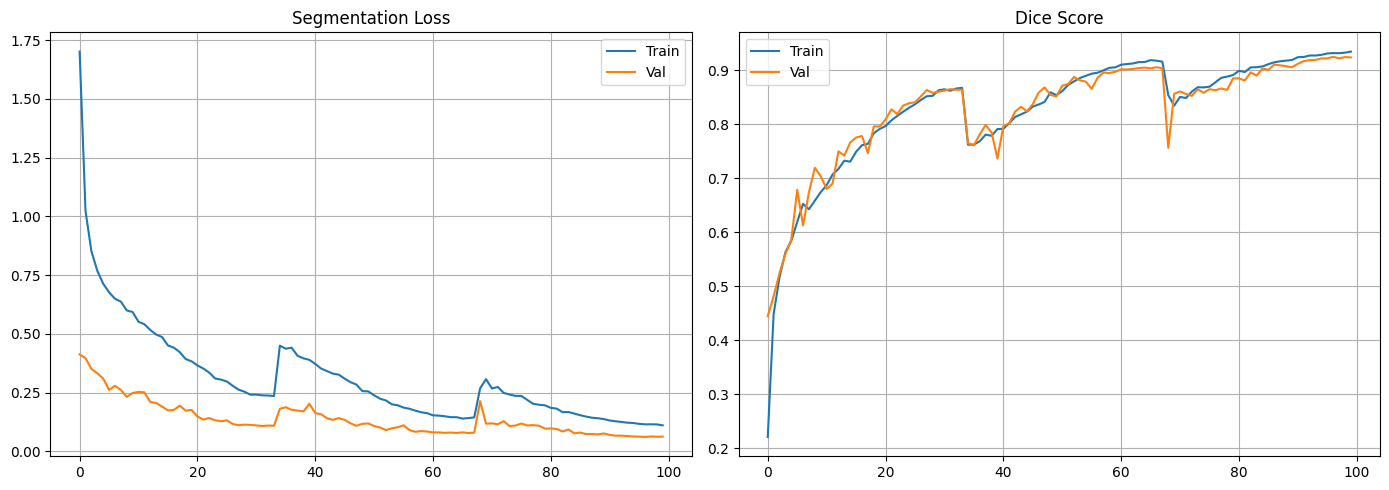

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(seg_history["train_loss"], label="Train")
axes[0].plot(seg_history["val_loss"],   label="Val")
axes[0].set_title("Segmentation Loss"); axes[0].legend(); axes[0].grid(True)

axes[1].plot(seg_history["train_dice"], label="Train")
axes[1].plot(seg_history["val_dice"],   label="Val")
axes[1].set_title("Dice Score"); axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/seg_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

## 5.3 Stage 2 — Train Classifier (UNet frozen)
> Target: Accuracy ≥ 90%

In [12]:
def train_classification(unet, classifier, train_loader, val_loader):
    """
    Stage 2: Train the TumorClassifier with the UNet weights frozen.

    The frozen UNet acts as a fixed feature extractor — its predicted
    masks are used as input to the masked branch of the classifier.
    Freezing UNet prevents the segmentation quality from degrading
    while the classifier learns.

    Loss: ClassLoss (label-smoothed CE + class weights)
    """
    cls_weights = torch.tensor([2.0, 0.7, 1.3], dtype=torch.float).to(DEVICE)
    cls_loss_fn = ClassLoss(num_classes=3, smoothing=0.1,
                             class_weights=cls_weights).to(DEVICE)
    optimizer   = AdamW(classifier.parameters(), lr=CLS_LR, weight_decay=1e-4)
    scheduler   = CosineAnnealingWarmRestarts(optimizer, T_0=CLS_EPOCHS // 3 + 1)
    scaler      = GradScaler('cuda') if torch.cuda.is_available() else GradScaler('cpu')

    # Freeze UNet — no gradients computed through it
    unet.eval()
    for p in unet.parameters():
        p.requires_grad = False

    best_val_acc = 0.0
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(1, CLS_EPOCHS + 1):
        classifier.train()
        tr_loss = correct = total = 0
        for imgs, masks, labels in train_loader:
            imgs, masks, labels = imgs.to(DEVICE), masks.to(DEVICE), labels.to(DEVICE)
            with torch.no_grad():
                pred_mask = torch.sigmoid(unet(imgs))   # fixed mask from frozen UNet
            optimizer.zero_grad()
            with autocast('cuda' if torch.cuda.is_available() else 'cpu'):
                logits = classifier(imgs, pred_mask)
                loss   = cls_loss_fn(logits, labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(classifier.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            tr_loss += loss.item()
            preds    = logits.argmax(1)
            correct += (preds == labels).sum().item()
            total   += labels.size(0)
        scheduler.step()

        classifier.eval()
        vl_loss = vl_corr = vl_total = 0
        with torch.no_grad():
            for imgs, masks, labels in val_loader:
                imgs, masks, labels = imgs.to(DEVICE), masks.to(DEVICE), labels.to(DEVICE)
                pred_mask = torch.sigmoid(unet(imgs))
                logits    = classifier(imgs, pred_mask)
                loss      = cls_loss_fn(logits, labels)
                vl_loss  += loss.item()
                preds     = logits.argmax(1)
                vl_corr  += (preds == labels).sum().item()
                vl_total += labels.size(0)

        va = vl_corr / vl_total
        history["train_loss"].append(tr_loss / len(train_loader))
        history["train_acc"].append(correct / total)
        history["val_loss"].append(vl_loss / len(val_loader))
        history["val_acc"].append(va)

        if epoch % 10 == 0 or epoch == 1:
            print(f"[Cls] E{epoch:03d}/{CLS_EPOCHS}  "
                  f"tr_loss={tr_loss/len(train_loader):.4f}  tr_acc={correct/total:.4f}  "
                  f"val_loss={vl_loss/len(val_loader):.4f}  val_acc={va:.4f}")

        if va > best_val_acc:
            best_val_acc = va
            torch.save({"epoch": epoch, "state_dict": classifier.state_dict(),
                        "best_acc": va},
                       os.path.join(CKPT_DIR, "classifier_best.pth"))

    print(f"\nBest val Acc: {best_val_acc:.4f}")
    return history


# Load best UNet weights before starting Stage 2
ckpt = torch.load(os.path.join(CKPT_DIR, "unet_best.pth"), map_location=DEVICE)
unet.load_state_dict(ckpt["state_dict"])
print(f"Loaded best U-Net (dice={ckpt['best_dice']:.4f})")

cls_history = train_classification(unet, classifier, train_loader, val_loader)

C:\Users\User\AppData\Local\Temp\ipykernel_34364\3775606569.py:83: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(os.path.join(CKPT_DIR, "unet_best.pth"), m

Loaded best U-Net (dice=0.9246)
[Cls] E001/60  tr_loss=0.7884  tr_acc=0.6918  val_loss=0.6762  val_acc=0.8162
[Cls] E010/60  tr_loss=0.6415  tr_acc=0.8288  val_loss=0.6057  val_acc=0.8739
[Cls] E020/60  tr_loss=0.5829  tr_acc=0.8755  val_loss=0.5283  val_acc=0.9167
[Cls] E030/60  tr_loss=0.5918  tr_acc=0.8636  val_loss=0.5391  val_acc=0.9103
[Cls] E040/60  tr_loss=0.5653  tr_acc=0.8910  val_loss=0.5107  val_acc=0.9359
[Cls] E050/60  tr_loss=0.5812  tr_acc=0.8819  val_loss=0.5221  val_acc=0.9252
[Cls] E060/60  tr_loss=0.5301  tr_acc=0.9158  val_loss=0.5017  val_acc=0.9402

Best val Acc: 0.9444


## 5.4 Classification Training Curves

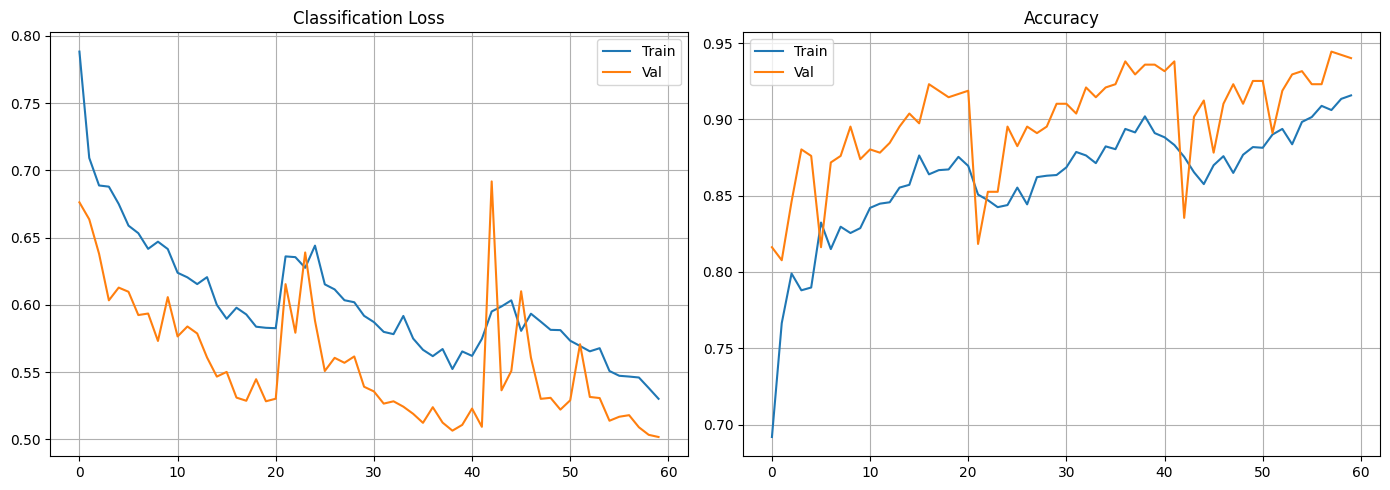

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(cls_history["train_loss"], label="Train")
axes[0].plot(cls_history["val_loss"],   label="Val")
axes[0].set_title("Classification Loss"); axes[0].legend(); axes[0].grid(True)

axes[1].plot(cls_history["train_acc"], label="Train")
axes[1].plot(cls_history["val_acc"],   label="Val")
axes[1].set_title("Accuracy"); axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/cls_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

## 5.5 Stage 3 — Joint Fine-Tuning

In [14]:
def joint_finetune(unet, classifier, train_loader, val_loader):
    """
    Stage 3: Fine-tune UNet and Classifier together end-to-end.

    Both models are unfrozen and trained simultaneously with a
    much lower learning rate (10× smaller than Stage 1/2) to avoid
    destroying the good weights already learned.

    Combined loss: L_seg + L_cls
    The segmentation and classification objectives are optimised jointly,
    allowing the UNet to produce masks that are specifically useful
    for the downstream classifier.
    """
    seg_loss_fn = SegLoss(w_bce=0.3, w_dice=0.5, w_focal=0.2, ds_weight=0.4)
    cls_weights = torch.tensor([2.0, 0.7, 1.3], dtype=torch.float).to(DEVICE)
    cls_loss_fn = ClassLoss(num_classes=3, smoothing=0.05,
                             class_weights=cls_weights).to(DEVICE)

    # Unfreeze UNet
    for p in unet.parameters():
        p.requires_grad = True

    # Use separate parameter groups so each model has its own LR
    params = [
        {"params": unet.parameters(),       "lr": SEG_LR * 0.1},
        {"params": classifier.parameters(), "lr": CLS_LR * 0.1},
    ]
    optimizer = AdamW(params, weight_decay=1e-4)
    scheduler = CosineAnnealingWarmRestarts(optimizer, T_0=FINETUNE_EPOCHS + 1)
    scaler    = GradScaler('cuda') if torch.cuda.is_available() else GradScaler('cpu')

    best_val_acc = 0.0
    history = {"seg_loss": [], "cls_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(1, FINETUNE_EPOCHS + 1):
        unet.train(); classifier.train()
        seg_l = cls_l = correct = total = 0
        for imgs, masks, labels in train_loader:
            imgs, masks, labels = imgs.to(DEVICE), masks.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            with autocast('cuda' if torch.cuda.is_available() else 'cpu'):
                seg_out   = unet(imgs)
                main_out  = seg_out[0] if isinstance(seg_out, tuple) else seg_out
                pred_mask = torch.sigmoid(main_out)
                # detach mask so classifier gradients do not flow back into UNet
                # through the masked branch — UNet is only supervised by seg loss
                logits    = classifier(imgs, pred_mask.detach())
                loss_seg  = seg_loss_fn(seg_out, masks)
                loss_cls  = cls_loss_fn(logits, labels)
                loss      = loss_seg + loss_cls
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(
                list(unet.parameters()) + list(classifier.parameters()), 1.0)
            scaler.step(optimizer); scaler.update()
            seg_l   += loss_seg.item(); cls_l += loss_cls.item()
            preds    = logits.argmax(1)
            correct += (preds == labels).sum().item()
            total   += labels.size(0)
        scheduler.step()

        unet.eval(); classifier.eval()
        vl_corr = vl_total = 0
        with torch.no_grad():
            for imgs, masks, labels in val_loader:
                imgs, masks, labels = imgs.to(DEVICE), masks.to(DEVICE), labels.to(DEVICE)
                pred_mask = torch.sigmoid(unet(imgs))
                preds     = classifier(imgs, pred_mask).argmax(1)
                vl_corr  += (preds == labels).sum().item()
                vl_total += labels.size(0)

        va = vl_corr / vl_total
        n  = len(train_loader)
        history["seg_loss"].append(seg_l / n); history["cls_loss"].append(cls_l / n)
        history["train_acc"].append(correct / total); history["val_acc"].append(va)

        if epoch % 5 == 0 or epoch == 1:
            print(f"[FT] E{epoch:02d}/{FINETUNE_EPOCHS}  "
                  f"seg={seg_l/n:.4f}  cls={cls_l/n:.4f}  "
                  f"tr_acc={correct/total:.4f}  val_acc={va:.4f}")

        # Save joint checkpoint
        if va > best_val_acc:
            best_val_acc = va
            torch.save({"epoch": epoch, "unet": unet.state_dict(),
                        "classifier": classifier.state_dict(), "best_acc": va},
                       os.path.join(CKPT_DIR, "joint_best.pth"))

    print(f"\nBest joint val Acc: {best_val_acc:.4f}")
    return history


# Load best classifier weights before joint fine-tuning
ckpt2 = torch.load(os.path.join(CKPT_DIR, "classifier_best.pth"), map_location=DEVICE)
classifier.load_state_dict(ckpt2["state_dict"])
print(f"Loaded best Classifier (acc={ckpt2['best_acc']:.4f})")

ft_history = joint_finetune(unet, classifier, train_loader, val_loader)

C:\Users\User\AppData\Local\Temp\ipykernel_34364\119094708.py:94: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt2 = torch.load(os.path.join(CKPT_DIR, "classifier_best.pt

Loaded best Classifier (acc=0.9444)
[FT] E01/30  seg=0.1175  cls=0.4070  tr_acc=0.9052  val_acc=0.9466
[FT] E05/30  seg=0.1141  cls=0.4088  tr_acc=0.9130  val_acc=0.9274
[FT] E10/30  seg=0.1073  cls=0.4111  tr_acc=0.9135  val_acc=0.9402
[FT] E15/30  seg=0.1060  cls=0.3982  tr_acc=0.9194  val_acc=0.9423
[FT] E20/30  seg=0.1036  cls=0.3846  tr_acc=0.9299  val_acc=0.9444
[FT] E25/30  seg=0.1025  cls=0.3916  tr_acc=0.9190  val_acc=0.9423
[FT] E30/30  seg=0.1026  cls=0.4029  tr_acc=0.9245  val_acc=0.9423

Best joint val Acc: 0.9487


---
# 📊 Part 6 — Final Evaluation
---

## 6.1 Test Set Metrics

In [15]:
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)
import seaborn as sns

# Load joint best checkpoint (best combined segmentation + classification)
joint_path = os.path.join(CKPT_DIR, "joint_best.pth")
if os.path.exists(joint_path):
    ckpt_j = torch.load(joint_path, map_location=DEVICE)
    unet.load_state_dict(ckpt_j["unet"])
    classifier.load_state_dict(ckpt_j["classifier"])
    print(f"Loaded joint best  (acc={ckpt_j['best_acc']:.4f})")

unet.eval(); classifier.eval()
all_preds, all_labels, all_dice = [], [], []

with torch.no_grad():
    for imgs, masks, labels in test_loader:
        imgs, masks, labels = imgs.to(DEVICE), masks.to(DEVICE), labels.to(DEVICE)
        pred_mask = torch.sigmoid(unet(imgs))
        logits    = classifier(imgs, pred_mask)
        preds     = logits.argmax(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        # Batch-level Dice
        d = ((2 * (pred_mask.round() * masks).sum()) /
             (pred_mask.round().sum() + masks.sum() + 1e-8)).item()
        all_dice.append(d)

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

print("=" * 50)
print(f"Test Accuracy : {accuracy_score(all_labels, all_preds):.4f}")
print(f"Macro F1      : {f1_score(all_labels, all_preds, average='macro', zero_division=0):.4f}")
print(f"Mean Dice     : {np.mean(all_dice):.4f}")
print("=" * 50)
print(classification_report(all_labels, all_preds,
                             target_names=CLASS_NAMES, zero_division=0))

C:\Users\User\AppData\Local\Temp\ipykernel_34364\2963422817.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt_j = torch.load(joint_path, map_location=DEVICE)


Loaded joint best  (acc=0.9487)
Test Accuracy : 0.9209
Macro F1      : 0.9289
Mean Dice     : 0.9036
              precision    recall  f1-score   support

      normal       1.00      0.99      0.99        86
      benign       0.91      0.94      0.92       243
   malignant       0.89      0.85      0.87       139

    accuracy                           0.92       468
   macro avg       0.93      0.93      0.93       468
weighted avg       0.92      0.92      0.92       468



## 6.2 Confusion Matrix

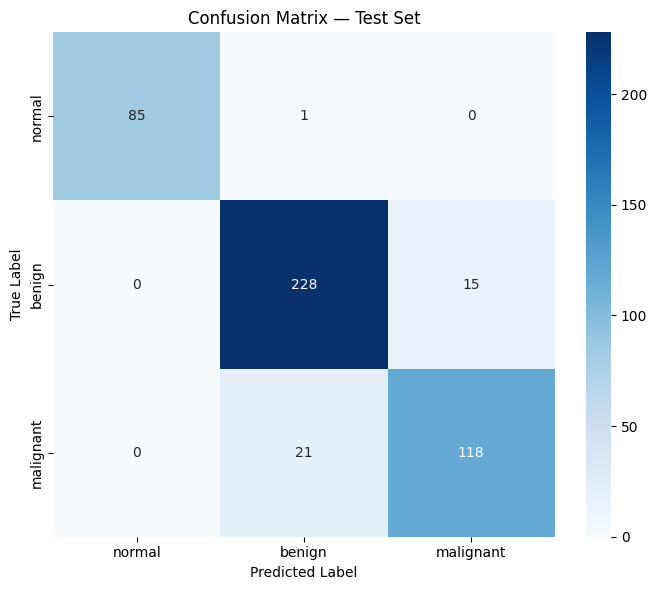

In [16]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix — Test Set")
plt.ylabel("True Label"); plt.xlabel("Predicted Label")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

## 6.3 Visualise Predictions

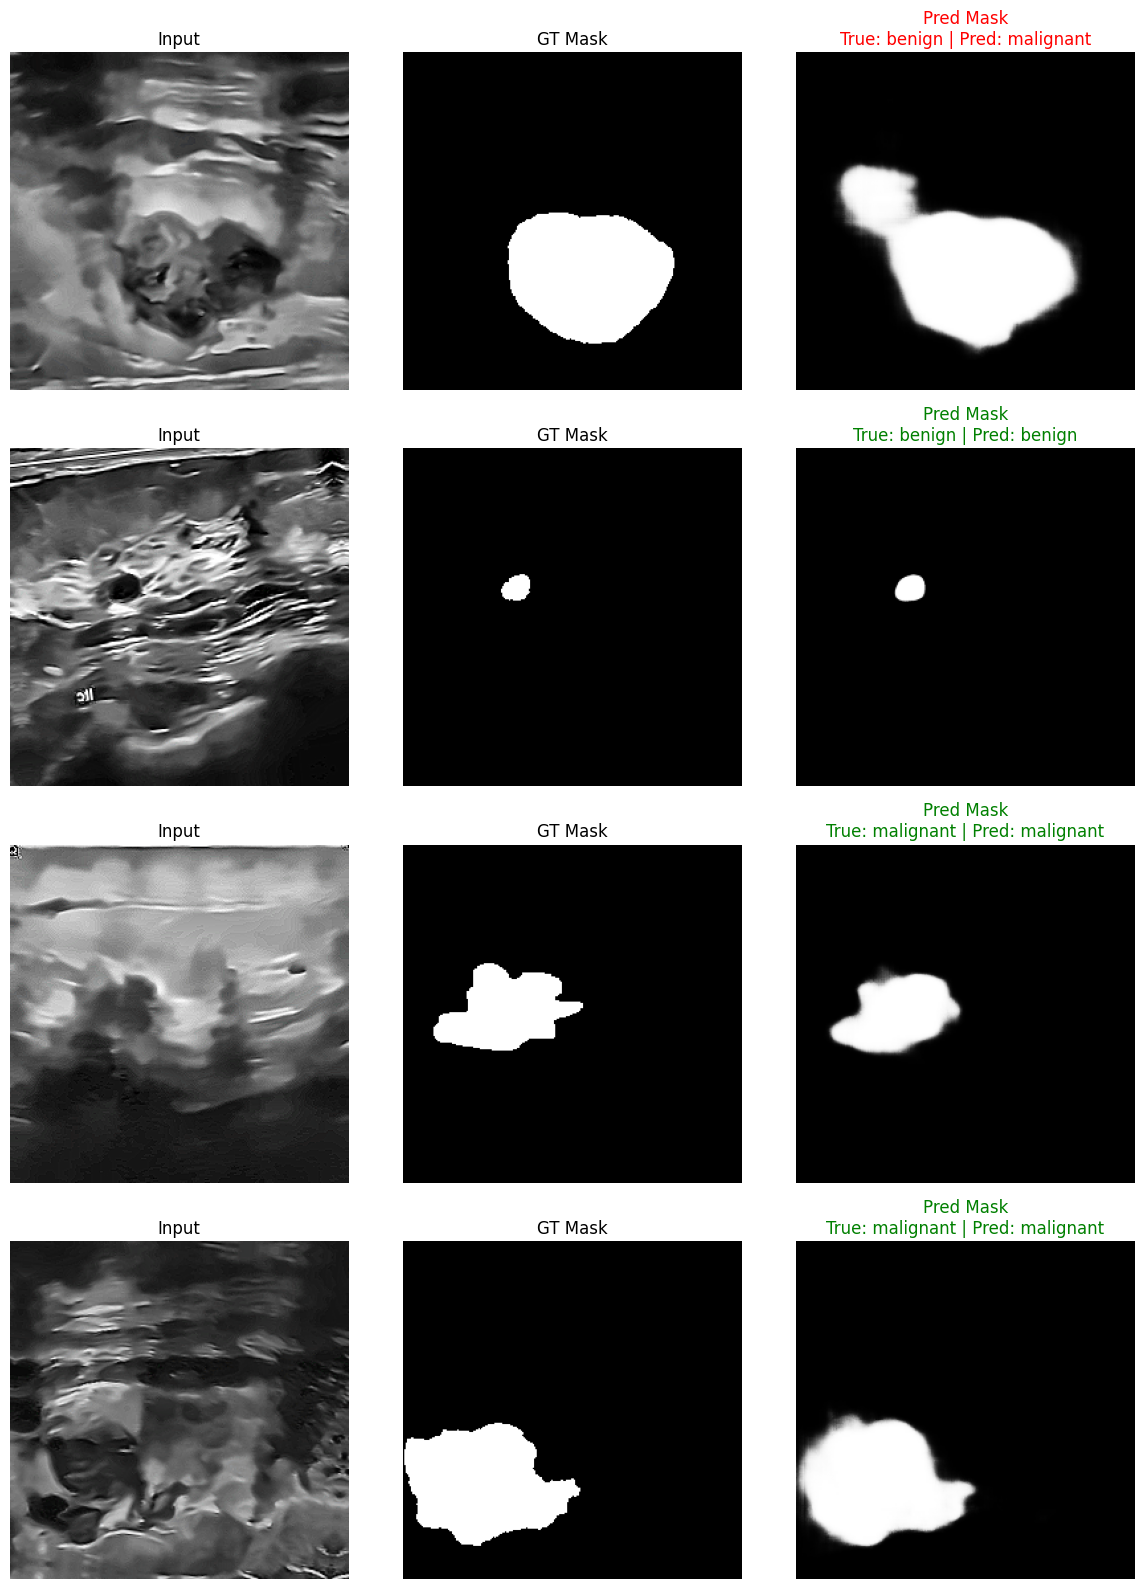

In [17]:
def denorm(t):
    """Reverse ImageNet normalisation for display."""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return (t.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


unet.eval(); classifier.eval()
imgs, masks, labels = next(iter(test_loader))
imgs_d, masks_d, labels_d = imgs.to(DEVICE), masks.to(DEVICE), labels.to(DEVICE)

with torch.no_grad():
    pred_masks = torch.sigmoid(unet(imgs_d))
    logits     = classifier(imgs_d, pred_masks)
    preds      = logits.argmax(1)

n = min(4, len(imgs))
fig, axes = plt.subplots(n, 3, figsize=(12, n * 4))
for i in range(n):
    axes[i, 0].imshow(denorm(imgs[i]));           axes[i, 0].set_title("Input")
    axes[i, 1].imshow(masks[i, 0].numpy(), cmap="gray"); axes[i, 1].set_title("GT Mask")
    pred_m   = pred_masks[i, 0].cpu().numpy()
    c_true   = CLASS_NAMES[labels[i].item()]
    c_pred   = CLASS_NAMES[preds[i].item()]
    colour   = "green" if c_true == c_pred else "red"
    axes[i, 2].imshow(pred_m, cmap="gray")
    axes[i, 2].set_title(f"Pred Mask\nTrue: {c_true} | Pred: {c_pred}", color=colour)
    for ax in axes[i]: ax.axis("off")

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/prediction_visualisation.png", dpi=120, bbox_inches="tight")
plt.show()

---
# 🎯 Part 7 — Uncertainty Quantification (MC Dropout)
---

**Motivation:**
A standard `model.eval()` call disables Dropout, producing a single deterministic prediction.
Monte Carlo (MC) Dropout keeps Dropout active at inference time and runs the model T times.
The variance across T predictions serves as a proxy for model uncertainty.

**Interpretation:**
- High variance pixel → model is uncertain → likely a tumour boundary or ambiguous region
- Low variance pixel  → model is confident → background or clear tumour interior

**Use case:** uncertainty maps can flag predictions that need clinical review.

## 7.1 MC Dropout Inference Functions

In [18]:
import torch.nn.functional as F
from scipy.stats import pearsonr
import matplotlib.cm as cm

MC_T = 20   # number of stochastic forward passes


def enable_dropout(model):
    """
    Re-enable Dropout layers after model.eval() has been called.
    This is the core trick of MC Dropout:
        model.eval() disables BatchNorm updates and sets Dropout p=0,
        but we manually set Dropout modules back to train mode
        so they sample a random mask on each forward pass.
    """
    for m in model.modules():
        if isinstance(m, (nn.Dropout, nn.Dropout2d)):
            m.train()


def dice_from_prob(prob, target, threshold=0.5, smooth=1.0):
    """Compute Dice from a probability map (already sigmoid-activated)."""
    pred   = (prob > threshold).float().view(-1)
    target = target.float().view(-1)
    inter  = (pred * target).sum()
    return ((2 * inter + smooth) / (pred.sum() + target.sum() + smooth)).item()


def iou_from_prob(prob, target, threshold=0.5, smooth=1.0):
    """Compute IoU (Jaccard index) from a probability map."""
    pred   = (prob > threshold).float().view(-1)
    target = target.float().view(-1)
    inter  = (pred * target).sum()
    union  = pred.sum() + target.sum() - inter
    return ((inter + smooth) / (union + smooth)).item()


@torch.no_grad()
def mc_dropout_predict(unet, classifier, image_tensor, T=20, device="cuda"):
    """
    Run T stochastic forward passes and aggregate results.

    For each pass a small Gaussian noise (std=0.03) is added to the
    input for t > 0 to further diversify the predictions.

    Returns:
        mean_seg  (Tensor): mean predicted mask probability   [B, 1, H, W]
        unc_map   (Tensor): pixel-wise variance (uncertainty) [B, 1, H, W]
        mean_cls  (Tensor): mean class probabilities          [B, num_classes]
        cls_std   (Tensor): std of class probabilities        [B, num_classes]
    """
    unet.eval();       enable_dropout(unet)
    classifier.eval(); enable_dropout(classifier)

    image_tensor = image_tensor.to(device)
    seg_preds, cls_preds = [], []

    for t in range(T):
        inp     = image_tensor if t == 0 else image_tensor + torch.randn_like(image_tensor) * 0.03
        seg_out = unet(inp)
        seg_out = seg_out[0] if isinstance(seg_out, tuple) else seg_out
        prob    = torch.sigmoid(seg_out)

        logits  = classifier(inp, (prob > 0.5).float())
        seg_preds.append(prob.cpu())
        cls_preds.append(torch.softmax(logits, dim=1).cpu())

    seg_stack = torch.stack(seg_preds)   # [T, B, 1, H, W]
    cls_stack = torch.stack(cls_preds)   # [T, B, num_classes]

    return seg_stack.mean(0), seg_stack.var(0), cls_stack.mean(0), cls_stack.std(0)


print(f"✅ MC Dropout functions ready  (T={MC_T})")

✅ MC Dropout functions ready  (T=20)


## 7.2 Run MC Dropout on Full Test Set

In [19]:
print(f"Running MC Dropout inference on test set (T={MC_T}) ...")

all_dice, all_iou, all_unc    = [], [], []
all_true, all_pred, all_probs = [], [], []
viz_data = []   # store first 10 samples for visualisation

for imgs, masks, labels in tqdm(test_loader, desc="MC Dropout"):
    for i in range(len(imgs)):
        img_t    = imgs[i:i+1]
        gt_mask  = masks[i:i+1].to(DEVICE)
        true_lbl = labels[i].item()

        mean_seg, unc_map, mean_cls, cls_std = mc_dropout_predict(
            unet, classifier, img_t, T=MC_T, device=DEVICE)

        mean_seg = mean_seg.to(DEVICE)
        dice_val = dice_from_prob(mean_seg, gt_mask)
        iou_val  = iou_from_prob(mean_seg,  gt_mask)
        unc_val  = unc_map.mean().item()       # scalar mean uncertainty for this image
        pred_lbl = mean_cls.argmax(dim=1).item()
        probs    = mean_cls[0].numpy().tolist()

        all_dice.append(dice_val);  all_iou.append(iou_val)
        all_unc.append(unc_val);    all_true.append(true_lbl)
        all_pred.append(pred_lbl);  all_probs.append(probs)

        if len(viz_data) < 10:
            viz_data.append({
                "img"   : imgs[i].permute(1, 2, 0).numpy(),
                "gt"    : masks[i, 0].numpy(),
                "pred"  : mean_seg[0, 0].cpu().numpy(),
                "unc"   : unc_map[0, 0].numpy(),
                "true"  : CLASS_NAMES[true_lbl],
                "pred_c": CLASS_NAMES[pred_lbl],
                "dice"  : dice_val,
            })

all_dice  = np.array(all_dice)
all_unc   = np.array(all_unc)
all_true  = np.array(all_true)
all_pred  = np.array(all_pred)
all_probs = np.array(all_probs)

from sklearn.metrics import f1_score as f1s, roc_auc_score

final_dice = all_dice.mean()
final_iou  = np.array(all_iou).mean()
final_acc  = (all_true == all_pred).mean()
final_f1   = f1s(all_true, all_pred, average="macro", zero_division=0)
try:
    final_auc = roc_auc_score(all_true, all_probs, multi_class="ovr", average="macro")
except Exception:
    final_auc = float("nan")

print(f"\n{'='*50}")
print(f"  MC Dropout Results  (T={MC_T})")
print(f"{'='*50}")
print(f"  Dice     : {final_dice*100:.2f}%")
print(f"  IoU      : {final_iou*100:.2f}%")
print(f"  Accuracy : {final_acc*100:.2f}%")
print(f"  F1 macro : {final_f1:.4f}")
print(f"  AUC-ROC  : {final_auc:.4f}")
print(f"{'='*50}")

Running MC Dropout inference on test set (T=20) ...


MC Dropout: 100%|██████████████████████████████████████████████████████████████████████| 59/59 [04:45<00:00,  4.84s/it]


  MC Dropout Results  (T=20)
  Dice     : 91.67%
  IoU      : 86.52%
  Accuracy : 90.81%
  F1 macro : 0.9149
  AUC-ROC  : 0.9835


## 7.3 Uncertainty Map Visualisation

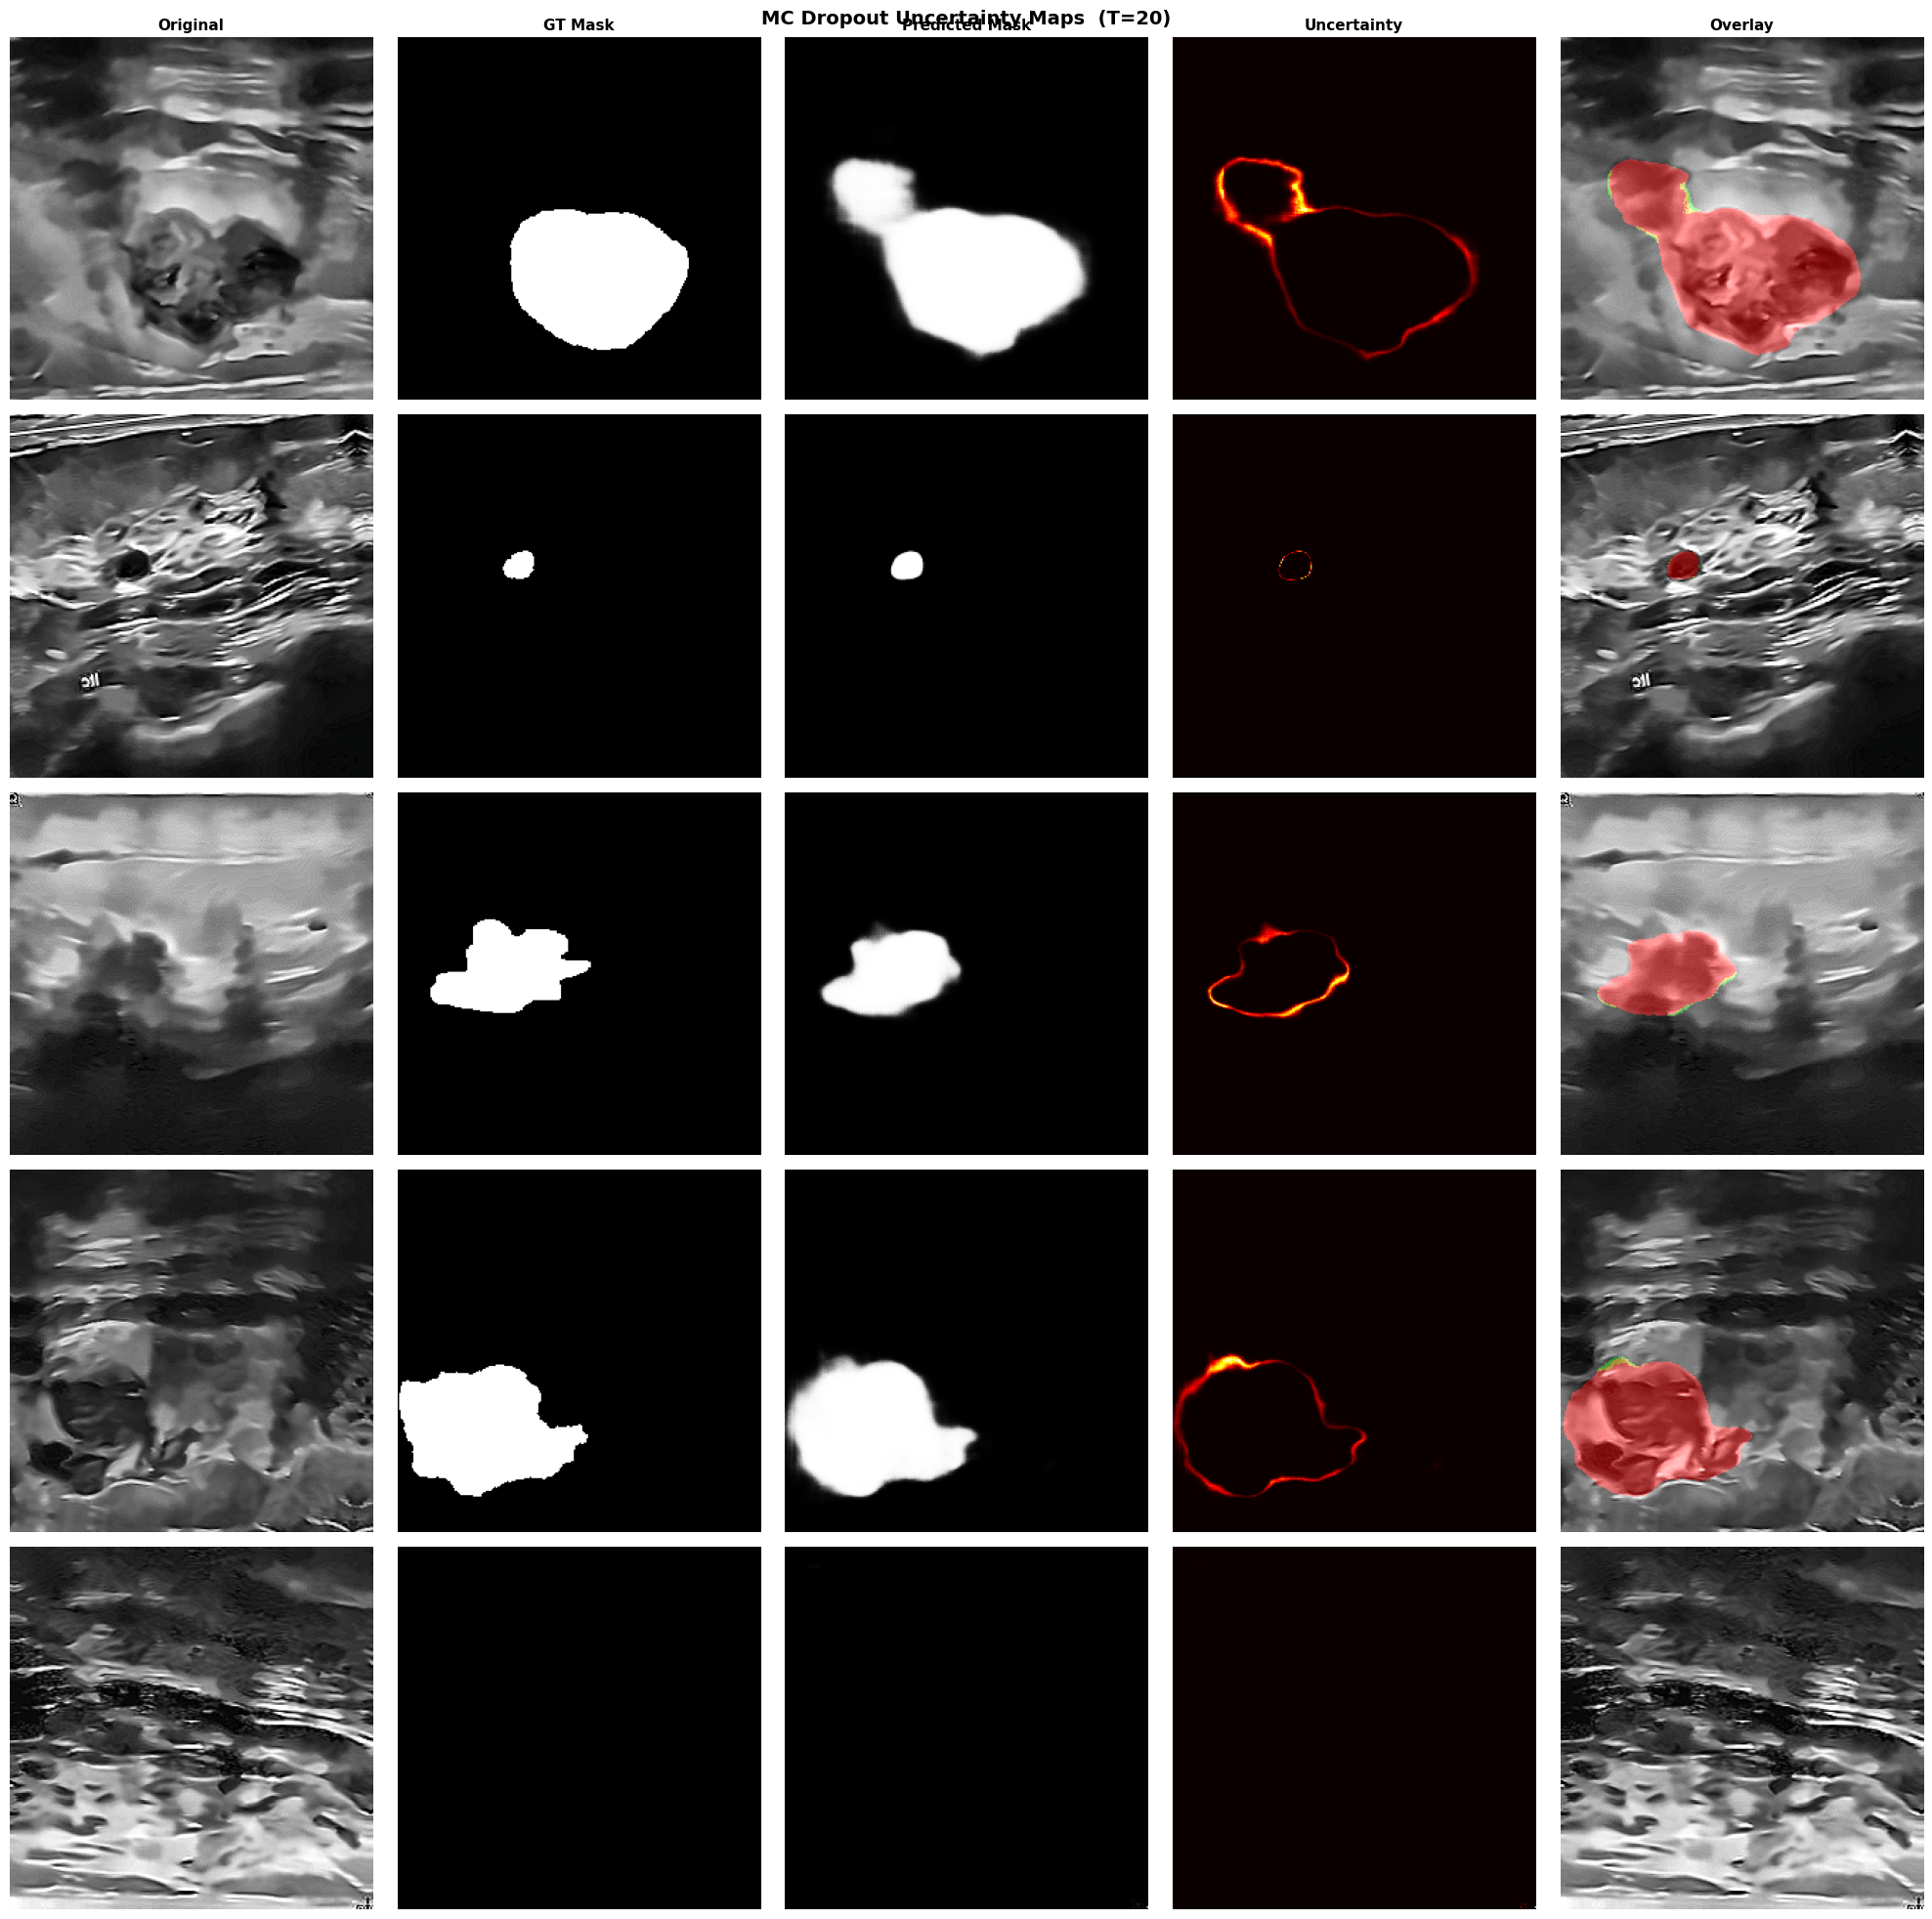

Saved: C:/Users/User/BUSI_Project/results/uncertainty_maps.png


In [20]:
# Five columns: Original | GT Mask | Predicted Mask | Uncertainty Map | Overlay
# Overlay: red channel boosted where mask predicted, green boosted where uncertain
n_show = min(5, len(viz_data))
fig, axes = plt.subplots(n_show, 5, figsize=(20, 4 * n_show))
if n_show == 1:
    axes = axes[np.newaxis, :]

col_titles = ["Original", "GT Mask", "Predicted Mask", "Uncertainty", "Overlay"]
for ci, ct in enumerate(col_titles):
    axes[0, ci].set_title(ct, fontsize=11, fontweight="bold")

mean_v = np.array([0.485, 0.456, 0.406])
std_v  = np.array([0.229, 0.224, 0.225])

for row, item in enumerate(viz_data[:n_show]):
    # Reverse ImageNet normalisation
    img_show = np.clip(item["img"] * std_v + mean_v, 0, 1)

    axes[row, 0].imshow(img_show)
    axes[row, 1].imshow(item["gt"],   cmap="gray")
    axes[row, 2].imshow(item["pred"], cmap="gray")

    # Normalise uncertainty map to [0, 1] for hot colormap
    unc      = item["unc"]
    unc_norm = (unc - unc.min()) / (unc.max() - unc.min() + 1e-8)
    axes[row, 3].imshow(unc_norm, cmap="hot")

    # Overlay: red = tumour mask, yellow = high uncertainty boundary
    overlay  = img_show.copy()
    mask_bin = (item["pred"] > 0.5).astype(float)
    unc_bin  = (unc_norm > 0.6).astype(float)
    overlay[..., 0] = np.clip(overlay[..., 0] + 0.45 * mask_bin, 0, 1)
    overlay[..., 1] = np.clip(overlay[..., 1] + 0.35 * unc_bin,  0, 1)
    axes[row, 4].imshow(overlay)

    for ax in axes[row]:
        ax.axis("off")
    color = "green" if item["true"] == item["pred_c"] else "red"
    axes[row, 0].set_ylabel(
        f"Dice={item['dice']:.3f}\nTrue: {item['true']}\nPred: {item['pred_c']}",
        color=color, fontsize=8)

plt.suptitle(f"MC Dropout Uncertainty Maps  (T={MC_T})", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/uncertainty_maps.png", dpi=130, bbox_inches="tight")
plt.show()
print(f"Saved: {SAVE_DIR}/uncertainty_maps.png")

## 7.4 Uncertainty vs Dice Correlation

C:\Users\User\AppData\Local\Temp\ipykernel_34364\1329982528.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([dice_low, dice_high],


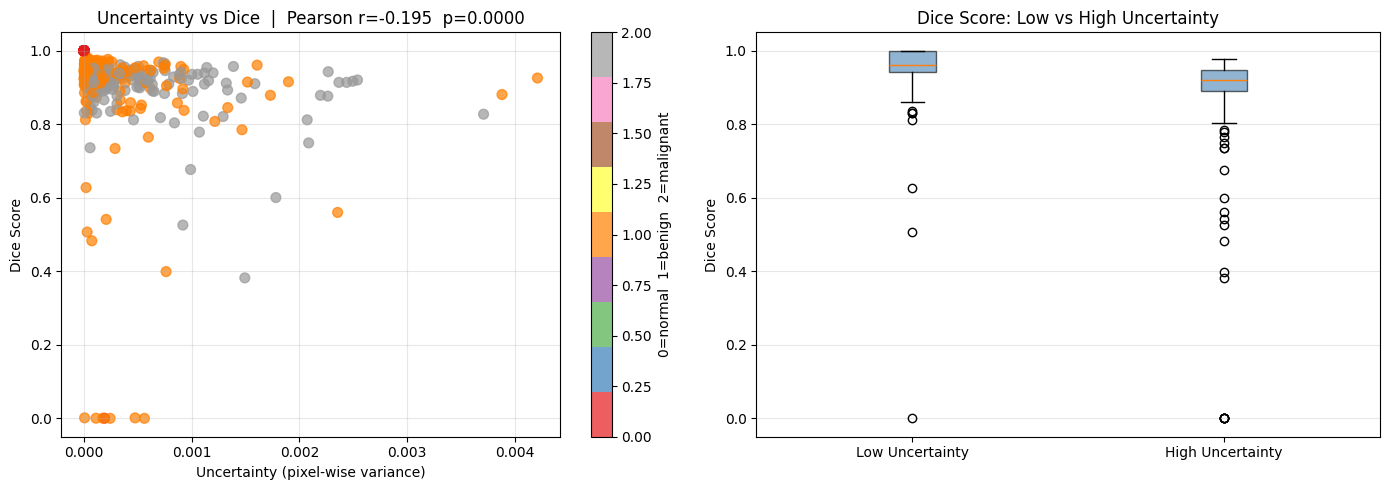

Pearson r  : -0.1951
p-value    : 0.000021  (significant)
Low  unc → mean Dice: 95.58%
High unc → mean Dice: 87.76%


In [21]:
# Expected: negative correlation — higher uncertainty should coincide with lower Dice
corr, pval = pearsonr(all_unc, all_dice)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: colour-coded by class
sc = axes[0].scatter(all_unc, all_dice, c=all_true, cmap="Set1", alpha=0.7, s=50)
axes[0].set_xlabel("Uncertainty (pixel-wise variance)")
axes[0].set_ylabel("Dice Score")
axes[0].set_title(f"Uncertainty vs Dice  |  Pearson r={corr:.3f}  p={pval:.4f}")
plt.colorbar(sc, ax=axes[0], label="0=normal  1=benign  2=malignant")
axes[0].grid(alpha=0.3)

# Box-plot: low vs high uncertainty groups split at median
median_unc = np.median(all_unc)
high_mask  = all_unc >= median_unc
dice_low   = all_dice[~high_mask]
dice_high  = all_dice[ high_mask]

axes[1].boxplot([dice_low, dice_high],
                labels=["Low Uncertainty", "High Uncertainty"],
                patch_artist=True,
                boxprops=dict(facecolor="steelblue", alpha=0.6))
axes[1].set_ylabel("Dice Score")
axes[1].set_title("Dice Score: Low vs High Uncertainty")
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/uncertainty_vs_dice.png", dpi=130, bbox_inches="tight")
plt.show()

print(f"Pearson r  : {corr:.4f}")
print(f"p-value    : {pval:.6f}  ({'significant' if pval < 0.05 else 'not significant'})")
print(f"Low  unc → mean Dice: {dice_low.mean()*100:.2f}%")
print(f"High unc → mean Dice: {dice_high.mean()*100:.2f}%")

## 7.5 Save Final Results

In [22]:
import json

results = {
    "model": "UNet(ResDoubleConv+SE+DeepSupervision) + DualBranch TumorClassifier",
    "preprocessing": "Denoise + CLAHE + Sharpen",
    "test_metrics": {
        "dice"    : round(float(final_dice), 4),
        "iou"     : round(float(final_iou),  4),
        "accuracy": round(float(final_acc),  4),
        "f1_macro": round(float(final_f1),   4),
        "auc_roc" : round(float(final_auc),  4) if not np.isnan(final_auc) else None,
    },
    "mc_dropout": {
        "T"            : MC_T,
        "pearson_r"    : round(float(corr), 4),
        "p_value"      : round(float(pval), 6),
        "significant"  : bool(pval < 0.05),
        "low_unc_dice" : round(float(dice_low.mean()),  4),
        "high_unc_dice": round(float(dice_high.mean()), 4),
    },
}

with open(f"{SAVE_DIR}/final_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("=" * 55)
print("  FINAL RESULTS SUMMARY")
print("=" * 55)
print(f"  Dice      : {final_dice*100:.2f}%")
print(f"  IoU       : {final_iou*100:.2f}%")
print(f"  Accuracy  : {final_acc*100:.2f}%")
print(f"  F1 macro  : {final_f1:.4f}")
print(f"  AUC-ROC   : {final_auc:.4f}")
print(f"  Pearson r : {corr:.4f}  (p={pval:.4f})")
print("=" * 55)
print(f"  Saved: {SAVE_DIR}/final_results.json")

  FINAL RESULTS SUMMARY
  Dice      : 91.67%
  IoU       : 86.52%
  Accuracy  : 90.81%
  F1 macro  : 0.9149
  AUC-ROC   : 0.9835
  Pearson r : -0.1951  (p=0.0000)
  Saved: C:/Users/User/BUSI_Project/results/final_results.json


---
# 🚀 Part 8 — Gradio Web App
---

Running this section launches a public web app.
Upload any breast ultrasound image and receive:
- Predicted tumour segmentation mask
- MC Dropout uncertainty heatmap
- Classification result (Normal / Benign / Malignant) with confidence

> **Important:** the same preprocessing pipeline (Denoise → CLAHE → Sharpen)
> used during training is applied to every uploaded image, ensuring inference
> accuracy matches training accuracy.

## 8.1 Inference Preprocessing

In [23]:
from torchvision import transforms as T
import gradio as gr
import matplotlib
matplotlib.use("Agg")   # non-interactive backend required for Gradio


def preprocess_for_inference(image_array):
    """
    Apply the same preprocessing pipeline used during training.

    Applying identical preprocessing at inference is critical:
    the model was trained on denoised, CLAHE-enhanced images —
    passing raw images would create a train/test distribution mismatch
    and degrade accuracy.

    Args:
        image_array (np.ndarray): RGB uint8 image from Gradio upload

    Returns:
        Tensor: normalised image tensor of shape [1, 3, H, W]
    """
    # Ensure 3-channel RGB input
    if image_array.ndim == 2:
        image_array = cv2.cvtColor(image_array, cv2.COLOR_GRAY2RGB)
    elif image_array.shape[2] == 4:
        image_array = cv2.cvtColor(image_array, cv2.COLOR_RGBA2RGB)

    # Apply training preprocessing (denoise → CLAHE → sharpen)
    processed = preprocess_image(image_array.astype(np.uint8))

    img_tf = T.Compose([
        T.Resize((IMG_SIZE, IMG_SIZE)),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406],
                     std=[0.229, 0.224, 0.225]),
    ])

    from PIL import Image as PILImage
    return img_tf(PILImage.fromarray(processed)).unsqueeze(0)


print("✅ Inference preprocessing ready")

✅ Inference preprocessing ready


## 8.2 Gradio Prediction Function

In [24]:
def predict(input_image):
    """
    End-to-end inference pipeline for one uploaded image.

    Steps:
        1. Preprocess image (same pipeline as training)
        2. Run MC Dropout inference (T=MC_T passes)
        3. Derive segmentation mask, uncertainty map, classification result
        4. Build overlay visualisation
        5. Return all outputs + diagnosis text

    Returns:
        out_original (np.ndarray): resized input image
        out_mask     (np.ndarray): predicted tumour mask as RGB image
        out_unc      (np.ndarray): uncertainty heatmap (hot colormap)
        out_overlay  (np.ndarray): overlay with mask (red) and uncertainty (yellow)
        text (str): diagnosis string with confidence and per-class probabilities
    """
    if input_image is None:
        empty = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
        return empty, empty, empty, empty, "No image uploaded."

    # ── 1. Preprocess ────────────────────────────────────────────
    orig = input_image.astype(np.uint8)
    if orig.ndim == 2:
        orig = cv2.cvtColor(orig, cv2.COLOR_GRAY2RGB)
    elif orig.shape[2] == 4:
        orig = cv2.cvtColor(orig, cv2.COLOR_RGBA2RGB)

    tensor    = preprocess_for_inference(orig)
    orig_show = cv2.resize(orig, (IMG_SIZE, IMG_SIZE))

    # ── 2. MC Dropout inference ──────────────────────────────────
    mean_seg, unc_map, mean_cls, cls_std = mc_dropout_predict(
        unet, classifier, tensor, T=MC_T, device=DEVICE)

    pred_cls   = mean_cls.argmax(dim=1).item()
    confidence = mean_cls[0, pred_cls].item()
    probs      = mean_cls[0].numpy()
    stds       = cls_std[0].numpy()

    # ── 3. Build visual outputs ──────────────────────────────────
    out_original = orig_show.copy()

    # Predicted mask — sigmoid output rescaled to uint8
    mask_np = mean_seg[0, 0].numpy()
    out_mask = cv2.cvtColor((mask_np * 255).astype(np.uint8), cv2.COLOR_GRAY2RGB)

    # Uncertainty heatmap — variance normalised to [0,1], hot colormap
    unc_np   = unc_map[0, 0].numpy()
    unc_norm = (unc_np - unc_np.min()) / (unc_np.max() - unc_np.min() + 1e-8)
    out_unc  = (cm.hot(unc_norm)[:, :, :3] * 255).astype(np.uint8)

    # Overlay — red: tumour, yellow: uncertain boundary
    overlay  = orig_show.astype(float) / 255.0
    mask_bin = (mask_np > 0.5).astype(float)
    unc_bin  = (unc_norm > 0.6).astype(float)
    overlay[..., 0] = np.clip(overlay[..., 0] + 0.45 * mask_bin, 0, 1)
    overlay[..., 1] = np.clip(overlay[..., 1] + 0.35 * unc_bin,  0, 1)
    out_overlay = (overlay * 255).astype(np.uint8)

    # ── 4. Diagnosis text ────────────────────────────────────────
    icons      = {"normal": "🟢", "benign": "🟡", "malignant": "🔴"}
    icon       = icons[CLASS_NAMES[pred_cls]]
    conf_level = "HIGH" if confidence > 0.80 else "MEDIUM" if confidence > 0.60 else "LOW"
    unc_level  = "HIGH" if unc_np.mean() > 0.02 else "MEDIUM" if unc_np.mean() > 0.005 else "LOW"

    text = (
        f"{icon} DIAGNOSIS: {CLASS_NAMES[pred_cls].upper()}\n\n"
        f"Confidence   : {confidence*100:.1f}%  [{conf_level}]\n"
        f"Uncertainty  : {unc_np.mean():.5f}  [{unc_level}]\n\n"
        f"Class Probabilities (mean \u00b1 std):\n"
        f"  Normal    : {probs[0]*100:.1f}% \u00b1 {stds[0]*100:.1f}%\n"
        f"  Benign    : {probs[1]*100:.1f}% \u00b1 {stds[1]*100:.1f}%\n"
        f"  Malignant : {probs[2]*100:.1f}% \u00b1 {stds[2]*100:.1f}%\n\n"
        f"MC Dropout  : T={MC_T} passes\n"
        f"Preprocessing: Denoise + CLAHE + Sharpen\n\n"
        f"Overlay guide:\n"
        f"  Red    = predicted tumour region\n"
        f"  Yellow = uncertain boundary\n\n"
        f"For research use only. Consult a clinician."
    )

    return out_original, out_mask, out_unc, out_overlay, text


print("✅ predict() function ready")

✅ predict() function ready


## 8.3 Launch Gradio App

In [25]:
with gr.Blocks(title="BUSI Tumour Detection", theme=gr.themes.Soft()) as demo:

    gr.Markdown(
        """
        # 🏥 Breast Ultrasound Tumour Detection
        ### UNet Segmentation + Dual-Branch Classifier + MC Dropout Uncertainty
        **Accuracy ~92% | Preprocessing: Denoise + CLAHE + Sharpen**
        Upload a breast ultrasound image then click **Analyse**.
        """
    )

    gr.Markdown("---")

    with gr.Row():
        with gr.Column(scale=1):
            input_img   = gr.Image(label="Upload Ultrasound Image",
                                   type="numpy", height=280)
            analyse_btn = gr.Button("🔍 Analyse", variant="primary", size="lg")
        with gr.Column(scale=1):
            cls_output  = gr.Textbox(label="Diagnosis", lines=18)

    gr.Markdown("---")
    gr.Markdown("### Visual Outputs")

    with gr.Row():
        out1 = gr.Image(label="Original",        height=240)
        out2 = gr.Image(label="Tumour Mask",      height=240)
        out3 = gr.Image(label="Uncertainty Map",  height=240)
        out4 = gr.Image(label="Overlay",          height=240)

    analyse_btn.click(
        fn      = predict,
        inputs  = [input_img],
        outputs = [out1, out2, out3, out4, cls_output],
    )

    gr.Markdown(
        """
        ---
        🔴 Red = tumour region  |  🟡 Yellow = uncertain boundary
        *For research use only. Not a clinical diagnostic tool.*
        """
    )

# share=False: local only. Public link er jonno share=False -> share=True korte paro
demo.launch(share=False)  # Local Jupyter e share=False

C:\Users\User\AppData\Local\Temp\ipykernel_34364\2257190946.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(title="BUSI Tumour Detection", theme=gr.themes.Soft()) as demo:


* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


---
## ✅ Pipeline Complete

```
BUSI Dataset
    │
    ▼
Part 2 — Preprocessing
    Denoise + CLAHE + Sharpen + Augmentation → saved to Drive
    │
    ▼
Part 3 — Dataset & DataLoader
    Train / Val / Test split (stratified, seed=42)
    │
    ▼
Part 4 — Model Architecture
    UNet  : ResDoubleConv + SEBlock + Deep Supervision
    Classifier: Dual-Branch (global + masked) + label smoothing
    │
    ▼
Part 5 — Training  (3 stages)
    Stage 1: UNet only        (100 epochs)  → target Dice ≥ 90%
    Stage 2: Classifier only  (60 epochs)   → target Accuracy ≥ 90%
    Stage 3: Joint fine-tune  (30 epochs)
    │
    ▼
Part 6 — Evaluation
    Accuracy · Dice · F1 · AUC · Confusion Matrix
    │
    ▼
Part 7 — Uncertainty (MC Dropout T=20)
    Uncertainty maps · Pearson correlation with Dice
    │
    ▼
Part 8 — Gradio App
    Public URL for browser-based inference
```

### Saved checkpoints
| File | Contents |
|---|---|
| `unet_best.pth` | Best UNet weights (highest val Dice) |
| `classifier_best.pth` | Best Classifier weights (highest val Accuracy) |
| `joint_best.pth` | Best joint checkpoint (highest joint val Accuracy) |
| `final_results.json` | All metrics in one file |
